In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.gaussian_process.kernels import RBF
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF
import os 

os.chdir('/Users/eochoa/Documents/Research_Abuj/M4AM/discovery_sampling/')

from utils import *

In [58]:
N=50
d=2
theta = np.random.rand(d)
x = np.random.multivariate_normal(np.zeros(d), np.eye(d), N)
f = x @ theta
    #f = np.power(f,2)
p = sigm(f)
y = 2*np.random.binomial(1,p)-1
y_ = (y+1)/2

In [59]:
x_star = np.random.multivariate_normal(np.zeros(d), np.eye(d), 1)
#X_star = np.random.multivariate_normal(np.zeros(d), np.eye(d), 20)

In [85]:
from scipy.linalg import solve
from scipy.special import erf, expit

LAMBDAS = np.array([0.41, 0.4, 0.37, 0.44, 0.39])[:, np.newaxis]
COEFS = np.array(
    [-1854.8214151, 3516.89893646, 221.29346712, 128.12323805, -2010.49422654]
)[:, np.newaxis]

import sklearn
def predict_proba_temporaries(self, X):
        """Return probability estimates for the test vector X.
        Parameters
        ----------
        X : array-like of shape (n_samples, n_features) or list of object
            Query points where the GP is evaluated for classification.
        Returns
        -------
        C : array-like of shape (n_samples, n_classes)
            Returns the probability of the samples for each class in
            the model. The columns correspond to the classes in sorted
            order, as they appear in the attribute ``classes_``.
        """
        #check_is_fitted(self)

        # Based on Algorithm 3.2 of GPML
        K_star = self.kernel_(self.X_train_, X)  # K_star =k(x_star)
        f_star = K_star.T.dot(self.y_train_ - self.pi_)  # Line 4
        v = solve(self.L_, self.W_sr_[:, np.newaxis] * K_star)  # Line 5
        # Line 6 (compute np.diag(v.T.dot(v)) via einsum)
        var_f_star = self.kernel_(X) - np.diag(np.einsum("ij,ij->j", v, v))

        # Line 7:
        # Approximate \int log(z) * N(z | f_star, var_f_star)
        # Approximation is due to Williams & Barber, "Bayesian Classification
        # with Gaussian Processes", Appendix A: Approximate the logistic
        # sigmoid by a linear combination of 5 error functions.
        # For information on how this integral can be computed see
        # blitiri.blogspot.de/2012/11/gaussian-integral-of-error-function.html
        #alpha = 1 / (2 * var_f_star)
        #gamma = LAMBDAS * f_star
        #integrals = (
        #    np.sqrt(np.pi / alpha)
        #    * erf(gamma * np.sqrt(alpha / (alpha + LAMBDAS**2)))
        #    / (2 * np.sqrt(var_f_star * 2 * np.pi))
        #)
        #pi_star = (COEFS * integrals).sum(axis=0) + 0.5 * COEFS.sum()
        # np.vstack((1 - pi_star, pi_star)).T, 
        
        return f_star, var_f_star

sklearn.gaussian_process._gpc._BinaryGaussianProcessClassifierLaplace.predict_proba_temporaries = predict_proba_temporaries


In [86]:
kernel = 1.0 * RBF(1.0)
gpc0 = GaussianProcessClassifier(kernel=kernel, random_state=0)
gpc0.fit(x, y)

GaussianProcessClassifier(kernel=1**2 * RBF(length_scale=1), random_state=0)

In [87]:
gpc0.kernel_

1.5**2 * RBF(length_scale=2.22)

In [88]:
gpc0.base_estimator_.f_cached

array([ 0.1154341 ,  0.20877385,  0.19464766,  0.72469909,  0.16278103,
        0.80833686, -0.34692119,  0.28844128,  0.268103  , -0.00796692,
        0.79255685,  0.28599046,  1.13662591,  1.05218435,  1.13726182,
       -0.38774068,  0.24400638,  1.31905029, -1.06448513,  0.62269161,
       -0.90270824,  0.02027343, -1.32462065, -0.11242242, -0.63346019,
       -0.75547046,  0.76987824, -0.50246073,  0.16476603, -0.09382737,
        0.28947558, -0.65354633,  0.80504847,  0.5385086 ,  1.43484771,
        1.30426303, -0.60484661,  1.065157  ,  0.2284475 , -0.62618677,
        0.54317001, -0.08910613,  0.21099424,  1.55474097, -0.74791198,
        0.43832047, -0.47209796,  0.46379007,  0.57681229,  1.18557658])

In [93]:
gpc0.base_estimator_.predict_proba_temporaries(x_star)

(array([0.22217903]), array([[0.23330213]]))

In [97]:
gpc0.predict_proba(x_star)

array([[0.44754275, 0.55245725]])

In [94]:
kernel = 1.5 * RBF(2.22)
gpc = GP_classifier(kernel, x, y)
gpc.init_priors()

In [95]:
gpc.update_posterior(tol=1e-3)

array([ 0.13761947,  0.21469102,  0.19890014,  0.64171332,  0.15717655,
        0.71977889, -0.2902194 ,  0.28332754,  0.26524251,  0.03140756,
        0.69332536,  0.28680754,  0.99466487,  0.92408868,  1.01026979,
       -0.29819341,  0.23432539,  1.16156104, -0.88491047,  0.56449092,
       -0.75438005,  0.0577577 , -1.12328653, -0.05978819, -0.50742219,
       -0.61376715,  0.69992195, -0.39465075,  0.1807219 , -0.05355641,
        0.26975428, -0.53600302,  0.71977942,  0.50166867,  1.25031774,
        1.10116876, -0.48473643,  0.94297905,  0.17999701, -0.50724018,
        0.50579368, -0.08202318,  0.22244522,  1.34116207, -0.61310104,
        0.4072127 , -0.38232541,  0.41893442,  0.53296607,  1.05014538])

In [98]:
gpc.posterior_pred(x_star)

array([0.45115872])

In [76]:
M = 100
pi_posterior = []
    
for i in range(M):
    
    #update posterior
    pi_posterior.append(gpc.posterior_pred_rand(x_star)[0])
pi_posterior

[0.6642840202868856,
 0.5198781786190315,
 0.4086021930463144,
 0.35962503990549505,
 0.46102221542824895,
 0.543899313944901,
 0.3982925939726765,
 0.3721125911345552,
 0.5540072926721671,
 0.33538193179855535,
 0.47472788914470926,
 0.5005429746860444,
 0.5263899387621038,
 0.47218641720451016,
 0.4533875851640265,
 0.508108720739035,
 0.38780925102871316,
 0.5801864916134715,
 0.4948791967770687,
 0.3268214827882427,
 0.4800950136995009,
 0.4219635529070571,
 0.38105770611334133,
 0.41631842576755956,
 0.3738622956352827,
 0.47478476504492023,
 0.4261253916618832,
 0.534130380203417,
 0.48421104276497734,
 0.3162643397337196,
 0.5402597193776043,
 0.45697679354427995,
 0.3370652993032557,
 0.33104983104380276,
 0.5486074430116985,
 0.3914833395973045,
 0.3796716126064317,
 0.5514371215498652,
 0.37130341515870224,
 0.29689855404319615,
 0.3864180959817739,
 0.3923864256983226,
 0.4162820003699028,
 0.5405535391550992,
 0.48825517911705724,
 0.416495539079482,
 0.5417440162666224,
 0

(0.44876478806536313,
 (array([ 5., 12., 15., 17., 14., 12., 11., 11.,  2.,  1.]),
  array([0.28736431, 0.32505628, 0.36274825, 0.40044022, 0.43813219,
         0.47582417, 0.51351614, 0.55120811, 0.58890008, 0.62659205,
         0.66428402]),
  <BarContainer object of 10 artists>))

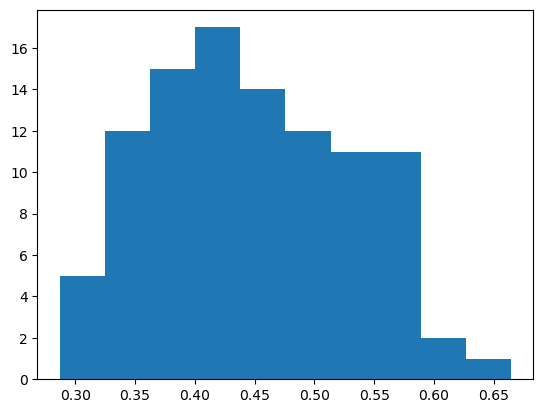

In [77]:
np.mean(pi_posterior), plt.hist(pi_posterior)